### Imports

In [17]:
# Import libraries
import os
import pandas as pd
import shap
import warnings
from tqdm import tqdm
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from urllib.parse import quote_plus
import numpy as np

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, ParameterGrid, train_test_split, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from utils.logger import setup_logger

from IPython.core.interactiveshell import InteractiveShell

# Set log level for matplotlib
plt.set_loglevel('warning')

# Enable IPython to display all the outputs
InteractiveShell.ast_node_interactivity = "all"

# Suppress all warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=UserWarning, module='lightgbm')

# Set pandas display options
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

### Class definition

In [18]:
class ModelTrainer:
    def __init__(self, test_set_date, cut_off_date,
                 target_groups,
                 numerical_cols,
                 categorical_cols,
                 boolean_cols,
                 target,
                 model_params,
                 scoring,
                 split_type='timeseries'):

        self.test_set_date = test_set_date
        self.cut_off_date = cut_off_date
        self.target_groups = target_groups
        self.numerical_cols = numerical_cols
        self.categorical_cols = categorical_cols
        self.boolean_cols = boolean_cols
        self.features = numerical_cols + categorical_cols + boolean_cols
        self.target = target
        self.model_params = model_params
        self.split_type = split_type
        self.scoring = scoring

        self.query = self.construct_query()
        self.df = self.fetch_and_prep_data(self.query)
        if self.df is None:
            raise ValueError("DataFrame could not be fetched and prepared.")

        self.X_train = None
        self.y_train = None
        self.X_test = None
        self.y_test = None

        self.best_model = None
        self.best_params = None
        self.feature_names = None
        self.results = []
        self.models_df = pd.DataFrame()
        self.shap_values = None
        self.grid_search_objects = []

        self.preprocessor_unscaled = self.create_preprocessor(scaling=False)
        self.preprocessor_scaled = self.create_preprocessor(scaling=True)
        self.models = self.create_models()

        self.logger = setup_logger('logs/')

    def construct_query(self):
        formatted_target_groups = "', '".join(self.target_groups)
        formatted_target_groups = f"('{formatted_target_groups}')"

        query = f'''
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.total_grp,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0 AND target_group IN {formatted_target_groups}
              AND start_date >= '{self.cut_off_date}'
            ORDER BY start_date
        '''
        return query

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        alchemy_con = f"mssql+pyodbc:///?odbc_connect={quoted}"
        engine = create_engine(alchemy_con)
        return engine

    def query_to_df(self, query):
        engine = self.create_sql_alchemy_engine()
        df_query = pd.read_sql_query(query, engine)
        return df_query

    def prep_dataframe(self, df_bereik):
        from sklearn.preprocessing import PowerTransformer

        df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        # df = df[df['ster_grp'] < 1000]
        # df = df[(df['ster_grp'] >= 80) & (df['ster_grp'] <= 130)]
        # df = df[df['npo3_grp_daynight'] < 10]

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        df = df.sort_values(by='start_date')

        # transform NPO3 GRPS
        pt = PowerTransformer(method='box-cox')
        constant = 1e-6  # Small constant to shift the data
        df['npo3_grp_daynight'] += constant
        df['npo3_grp_primetime'] += constant
        df['npo3_grp_total'] += constant

        df['npo3_grp_daynight'] = pt.fit_transform(df[['npo3_grp_daynight']])
        df['npo3_grp_primetime'] = pt.fit_transform(df[['npo3_grp_primetime']])
        df['npo3_grp_total'] = pt.fit_transform(df[['npo3_grp_total']])


        # Add 300 random rows that have a base value of 0 GRPs and bereik
        non_grp_columns = ['start_date', 'end_date', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                            'timef_start_day', 'timef_end_day', 'timef_start_week', 'timef_end_week', 'timef_start_month',
                            'timef_end_month', 'timef_start_year', 'timef_end_year', 'timef_start_season', 'timef_end_season',
                            'target_group', 'advertiser', 'product', 'mock_campaign', 'alcohol_kansspelen', 'new_data']

        sampled_df = df.sample(n=600, random_state=42).reset_index(drop=True)
        sampled_df_zeroed = sampled_df.copy()
        for column in sampled_df_zeroed.columns:
            if column not in non_grp_columns:
                sampled_df_zeroed[column] = 0

        df_combined = pd.concat([df, sampled_df_zeroed], ignore_index=True)

        return df

    def filter_outliers(self, df):

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        return df

    def fetch_and_prep_data(self, query):
        try:
            df = self.query_to_df(query)
            df = self.prep_dataframe(df)
            df = self.filter_outliers(df)
        except Exception as e:
            print(f"Error executing query: {str(e)}")
            return None
        return df

    def split_and_shuffle_data(self, df, test_set_date=None):
        if test_set_date:
            end_date = pd.to_datetime('2024-04-01')
            # Time Series Split
            train_data = df[df['start_date'] < test_set_date]
            test_data = df[(df['start_date'] >= test_set_date) & (df['start_date'] <= end_date)]
            X_train = train_data[self.features]
            y_train = train_data[self.target]
            X_test = test_data[self.features]
            y_test = test_data[self.target]

        else:
            # Random Split
            X = df[self.features]
            y = df[self.target]
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test

    def create_preprocessor(self, scaling=True):
        transformers = []

        numerical_transformer_steps = [('imputer', SimpleImputer(strategy='mean'))]
        if scaling:
            numerical_transformer_steps.append(('scaler', StandardScaler()))

        numerical_transformer = Pipeline(steps=numerical_transformer_steps)
        transformers.append(('num', numerical_transformer, self.numerical_cols))

        if self.categorical_cols:
            categorical_transformer = Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])
            transformers.append(('cat', categorical_transformer, self.categorical_cols))

        if self.boolean_cols:
            boolean_transformer = Pipeline(steps=[
                ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
                ('imputer', SimpleImputer(strategy='most_frequent'))])
            transformers.append(('bool', boolean_transformer, self.boolean_cols))

        preprocessor = ColumnTransformer(transformers=transformers)

        return preprocessor

    def create_models(self):
        models = []
        for model_info in self.model_params:
            models.append({
                'name': model_info['name'],
                'model': model_info['model'],
                'params': model_info['params'],
                'preprocessor': self.preprocessor_unscaled if model_info['scaling'] == 'unscaled' else self.preprocessor_scaled
            })

        return models

    def grid_search_models(self, split_type='timeseries'):
        models_data = {
            'Model': [],
            'Parameters': [],
            'R2 Train': [],
            'R2 Test': [],
            'MSE Train': [],
            'MSE Test': [],
            'MAE Train': [],
            'MAE Test': []
        }

        for model_info in self.models:
            pipeline = Pipeline(steps=[
                ('preprocessor', model_info['preprocessor']),
                ('model', model_info['model'])
            ])

            if self.split_type == 'timeseries':
                self.split_and_shuffle_data(self.df, self.test_set_date)
                cv = TimeSeriesSplit(n_splits=5)
            elif self.split_type == 'random':
                self.split_and_shuffle_data(self.df)
                cv = KFold(n_splits=5, shuffle=True, random_state=42)

            grid_search = GridSearchCV(
                estimator=pipeline,
                param_grid=model_info['params'],
                cv=cv,
                scoring=self.scoring,
                n_jobs=-1,
                return_train_score=True,
                verbose=2
            )

            grid_search.fit(self.X_train, self.y_train)

            self.grid_search_objects.append(grid_search)
            results_df = pd.DataFrame(grid_search.cv_results_)
            self.results.append(results_df)

            if grid_search.best_score_ > (self.best_score if self.best_model else float('-inf')):
                self.best_score = grid_search.best_score_
                self.best_model = grid_search.best_estimator_
                self.best_params = grid_search.best_params_

            y_train_pred = grid_search.predict(self.X_train)
            y_test_pred = grid_search.predict(self.X_test)

            models_data['Model'].append(model_info['name'])
            models_data['Parameters'].append(self.best_params)
            models_data['R2 Train'].append(r2_score(self.y_train, y_train_pred))
            models_data['R2 Test'].append(r2_score(self.y_test, y_test_pred))
            models_data['MSE Train'].append(mean_squared_error(self.y_train, y_train_pred))
            models_data['MSE Test'].append(mean_squared_error(self.y_test, y_test_pred))
            models_data['MAE Train'].append(mean_absolute_error(self.y_train, y_train_pred))
            models_data['MAE Test'].append(mean_absolute_error(self.y_test, y_test_pred))

        self.models_df = pd.DataFrame(models_data)

        self.logger.info("TEST_SET_DATE: %s", self.test_set_date)
        self.logger.info("CUT_OFF_DATE: %s ", self.cut_off_date)
        self.logger.info("TARGET_GROUPS: %s ", self.target_groups)
        self.logger.info("FEATURES: %s ", self.features)
        self.logger.info("Scoring: %s ", self.scoring)
        self.logger.info("Split-type: %s ", self.split_type)
        self.logger.info(f"X_train shape: {self.X_train.shape}, X_test shape: {self.X_test.shape}, y_train shape: {self.y_train.shape}, y_test shape: {self.y_test.shape}")

        # Log the results for all models
        self.logger.info('Best Parameters for All Models:')
        for idx, row in self.models_df.iterrows():
            model_name = row['Model']
            params = row['Parameters']
            self.logger.info('%s:', model_name)
            for param, value in params.items():
                self.logger.info('  %s: %s', param, value)

        models_df_no_params = self.models_df.drop(columns=['Parameters'])
        self.logger.info("Models Scores:\n%s", models_df_no_params.to_string(index=False))
        self.logger.info("----------------------------------------------------------------------")

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        self.feature_names = feature_names

        return feature_names

    def extract_and_visualize_shap_values(self, top_n = 10, plot_instance = 0):
        if self.best_model is None:
            print("No best model found. Please run grid_search_models first.")
            return

        explainer = shap.Explainer(self.best_model.named_steps['model'])
        expected_value = explainer.expected_value
        self.shap_values = explainer(self.best_model.named_steps['preprocessor'].transform(self.X_test))
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])

        # Print SHAP values
        shap_df = pd.DataFrame(self.shap_values.values, columns=feature_names)
        shap_importance = shap_df.abs().mean().sort_values(ascending=False)
        print(shap_importance[:top_n])

        self.visualize_shap_values(self.shap_values, self.best_model.named_steps['preprocessor'].transform(self.X_test), feature_names, plot_instance)

    def visualize_shap_values(self, shap_values, X_test_transformed, feature_names, plot_instance):
        if shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

        # Create a SHAP values object with feature names
        custom_shap_values = shap.Explanation(
            values=shap_values.values,
            base_values=shap_values.base_values,
            data=X_test_transformed,
            feature_names=feature_names
        )

        # Summary plot
        shap.summary_plot(shap_values, X_test_transformed_df, plot_size=[7, 5])

        # Bar plot of feature importances
        shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", plot_size=[7, 5])

        # Force plot for the first instance (can be adjusted to show more instances)
        print(X_test_transformed_df.iloc[plot_instance])
        shap.force_plot(
            shap_values[plot_instance].base_values,
            shap_values[plot_instance].values,
            X_test_transformed_df.iloc[plot_instance],
            feature_names=feature_names,
            matplotlib=True,
            show=True,
            figsize=(35, 3)
        )

        # Waterfall plot for the first instance (can be adjusted to show more instances)
        plt.figure(figsize=(7, 5))
        shap.plots.waterfall(custom_shap_values[plot_instance])
        plt.show()

    def plot_dependence(self, feature_name_or_index):
        if self.shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])
        X_test_transformed_df = pd.DataFrame(self.best_model.named_steps['preprocessor'].transform(self.X_test), columns=feature_names)

        # Plot dependence plot
        if isinstance(feature_name_or_index, int):
            shap.dependence_plot(feature_name_or_index, self.shap_values.values, X_test_transformed_df, feature_names=feature_names)
        elif isinstance(feature_name_or_index, str):
            feature_index = feature_names.index(feature_name_or_index)
            shap.dependence_plot(feature_index, self.shap_values.values, X_test_transformed_df, feature_names=feature_names)
        else:
            print("Invalid type for feature_name_or_index. Use an int or str.")

        # Plot Partial Dependence Plot
        fig, ax = plt.subplots(figsize=(8, 6))
        display = PartialDependenceDisplay.from_estimator(
            trainer.best_model, trainer.X_train, features=[0, feature_name_or_index], feature_names=trainer.feature_names, ax=ax, verbose=-1
        )

        # Generate Partial Dependence Plot for GRPs
        fig, ax = plt.subplots(figsize=(8, 6))
        PartialDependenceDisplay.from_estimator(
            trainer.best_model,
            trainer.X_train,
            features=[feature_name_or_index],
            feature_names=trainer.feature_names,
            ax=ax
        )
        plt.title('Partial Dependence Plot')
        plt.show();

    def extract_models_details(self):
        if self.best_model is None:
            self.logger.info("No best model found. Please run grid_search_models first.")
            return

        # Extract model details
        preprocessor = self.best_model.named_steps['preprocessor']
        best_model = self.best_model.named_steps['model']
        best_params = self.best_params

        # Extract feature names
        feature_names = self.get_feature_names(preprocessor)
        # Format feature names with a newline after every 7 features
        feature_names_chunks = [', '.join(feature_names[i:i + 7]) for i in range(0, len(feature_names), 7)]
        feature_names_str = '\n                                '.join(feature_names_chunks)

        # # Wrap lines at 80 characters
        # feature_names_str = '\n'.join(feature_names_str[i:i + 80] for i in range(0, len(feature_names_str), 80))

        # Extract preprocessor scaling
        scaling = 'scaled' if 'scaler' in preprocessor.named_transformers_ else 'unscaled'

        # Log the details
        self.logger.info('Best Model: %s', self.best_model.named_steps['model'].__class__.__name__)
        self.logger.info('Feature Names: %s', feature_names_str)
        self.logger.info('Best params: %s', best_params)
        self.logger.info('Preprocessor Scaling: %s', scaling)
        # self.logger.info('Model Details: %s', best_model)
        self.logger.info("-------------------------------------------------------------------------------------------------------------------------------------------------------------")

    def predict_new_data(self, new_df):
        try:
            # Select features from the prepared DataFrame
            X_new = new_df[self.features]

            # Preprocess the new data using the same preprocessor used in the best model
            X_preprocessed = self.best_model.named_steps['preprocessor'].transform(X_new)

            # Predict using the best model
            predictions = self.best_model.named_steps['model'].predict(X_preprocessed)

            # Prepare the results DataFrame
            results_df = X_new.copy()
            results_df['Predictions'] = predictions

            # Add the real target values if provided
            if 'ster_1+_total' in new_df.columns:
                results_df['ster_1+_total'] = new_df['ster_1+_total']
                # Calculate residuals
                results_df['Residuals'] = results_df['ster_1+_total'] - results_df['Predictions']
            else:
                print("Warning: 'ster_1+_total' column not found in the new data.")

            # Save the results to an Excel file
            results_df.to_excel('results_df', index=False)

            return results_df

        except Exception as e:
            print(f"Error during prediction: {str(e)}")
            return None

    def save_model(self, file_path):
        """
        Save the trained model to a file.
        """
        joblib.dump(self.best_model, file_path)
        print(f"Model saved to {file_path}")

    def load_model(self, file_path):
        """
        Load a model from a file.
        """
        self.best_model = joblib.load(file_path)
        print(f"Model loaded from {file_path}")


## Parameters


In [19]:
# Define the parameters for the ModelTrainer instance
TEST_SET_DATE = pd.to_datetime('2024-03-01')     # start datum van test set (als timeseries wordt aanghouden)
CUT_OFF_DATE = '2021-01-01'                      # inclusief of exclusief oude data
TARGET_GROUPS = ['68+']                         # kan ook met meerdere target groups als feature

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime',
                  'npo2_grp_daynight', 'npo2_grp_primetime',
                  'npo3_grp_daynight', 'npo3_grp_primetime',
                  'regio_grp_daynight', 'regio_grp_primetime',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap', 'timef_duration_days',
                #   'timef_start_month', 'timef_end_month',
                  'timef_start_year', 'timef_end_year',
                  'timef_start_week', 'timef_end_week',
                #   'timef_end_day', 'timef_start_day'
                  ]

CATEGORICAL_COLS = [
                    # 'timef_start_season',
                    # 'timef_end_season'
                    ]

BOOLEAN_COLS = ['alcohol_kansspelen', 'new_data']

TARGET = 'ster_1+_total'

# Tweaken kan met deze parameters (of meerdere modellen) met al dan niet scaling. Dit is zo'n beetje het minimale (met 2 modellen) om te testen.

MODEL_PARAMS = [
    # {
    #     'name': 'LGBM without scaling 20-49',
    #     'model': LGBMRegressor(),
    #     'params': {
    #         'model__objective': ['regression'],
    #         'model__metric': ['rmse'],
    #         'model__boosting_type': ['goss'],
    #         'model__learning_rate': [0.05],
    #         'model__num_leaves': [36],
    #         'model__max_depth': [12],
    #         'model__subsample': [0.5],
    #         'model__colsample_bytree': [1.0],
    #         'model__reg_alpha': [2.5],  # This replaces 'lambda_l1'
    #         'model__reg_lambda': [2],  # This replaces 'lambda_l2'
    #         'model__max_bin': [2048],
    #         'model__n_estimators': [100],
    #         'model__drop_rate': [0.2],
    #         'model__min_split_gain': [0.0],
    #         'model__subsample_freq': [1, 3],
    #         'model__verbose': [1],
    #         'model__seed': [42],
    #     },
    #     'scaling': 'unscaled'
    # },
    {
        'name': 'LGBM without scaling 25-67',
        'model': LGBMRegressor(),
        'params': {
            'model__objective': ['regression'],
            'model__metric': ['rmse'],
            'model__boosting_type': ['gbdt'],
            'model__learning_rate': [0.07],
            'model__num_leaves': [41],
            'model__max_depth': [6],
            'model__subsample': [0.5],
            'model__colsample_bytree': [1.0],
            'model__reg_alpha': [2.5],  # This replaces 'lambda_l1'
            'model__reg_lambda': [2],  # This replaces 'lambda_l2'
            'model__max_bin': [2048],
            'model__n_estimators': [100],
            'model__drop_rate': [0.2],
            'model__min_split_gain': [0.0],
            'model__subsample_freq': [1],
            'model__verbose': [1],
            'model__seed': [42],
        },
        'scaling': 'unscaled'
    },
    # {
    #     'name': 'LGBM without scaling 68+',
    #     'model': LGBMRegressor(),
    #     'params': {
    #         'model__objective': ['regression'],
    #         'model__metric': ['rmse'],
    #         'model__boosting_type': ['gbdt'],
    #         'model__learning_rate': [0.07],
    #         'model__num_leaves': [36],
    #         'model__max_depth': [8],
    #         'model__subsample': [0.5],
    #         'model__colsample_bytree': [0.8],
    #         'model__reg_alpha': [1.5],
    #         'model__reg_lambda': [1.5],
    #         'model__max_bin': [2048],
    #         'model__n_estimators': [150],
    #         'model__drop_rate': [0],
    #         'model__min_split_gain': [0.1],
    #         'model__subsample_freq': [3],
    #         'model__verbose': [1],
    #         'model__seed': [42],
    #     },
    #     'scaling': 'unscaled'
    # }
]

# Create an instance of ModelTrainer
trainer = ModelTrainer(
    test_set_date=TEST_SET_DATE,
    cut_off_date=CUT_OFF_DATE,
    target_groups=TARGET_GROUPS,
    numerical_cols=NUMERICAL_COLS,
    categorical_cols=CATEGORICAL_COLS,
    boolean_cols=BOOLEAN_COLS,
    target=TARGET,
    model_params=MODEL_PARAMS,
    scoring = 'neg_mean_squared_error',       # r2, mae, neg_mean_squared_error
    split_type ='timeseries',                 # random of timeseries
)


## Visuals

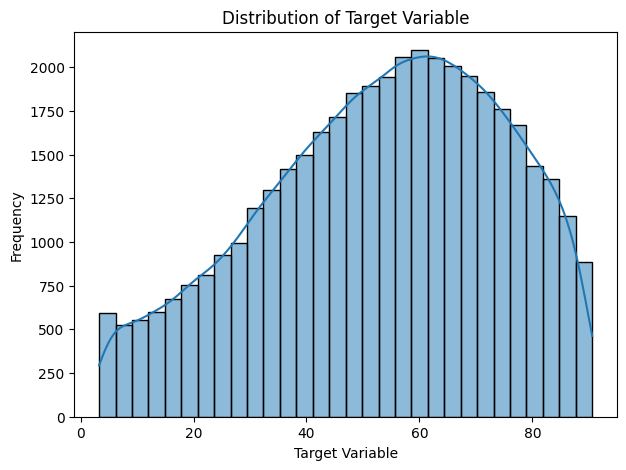

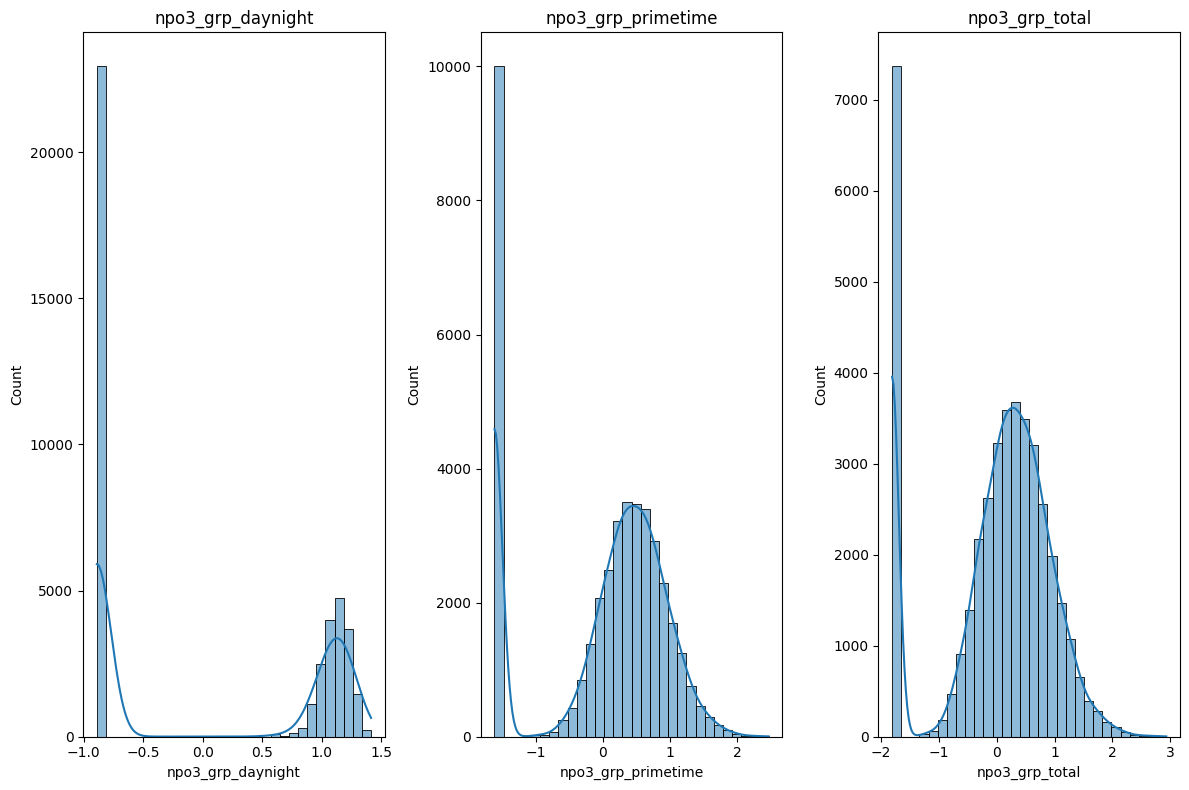

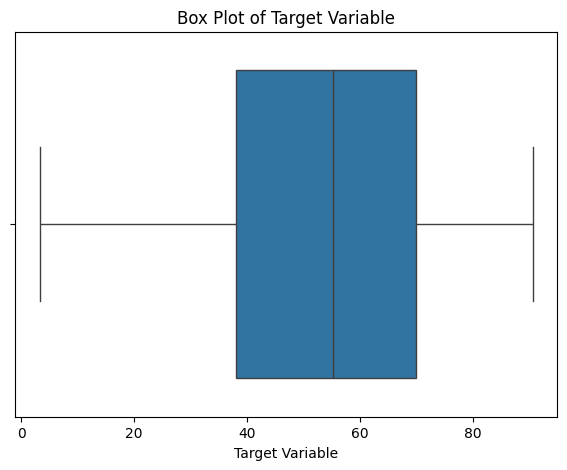

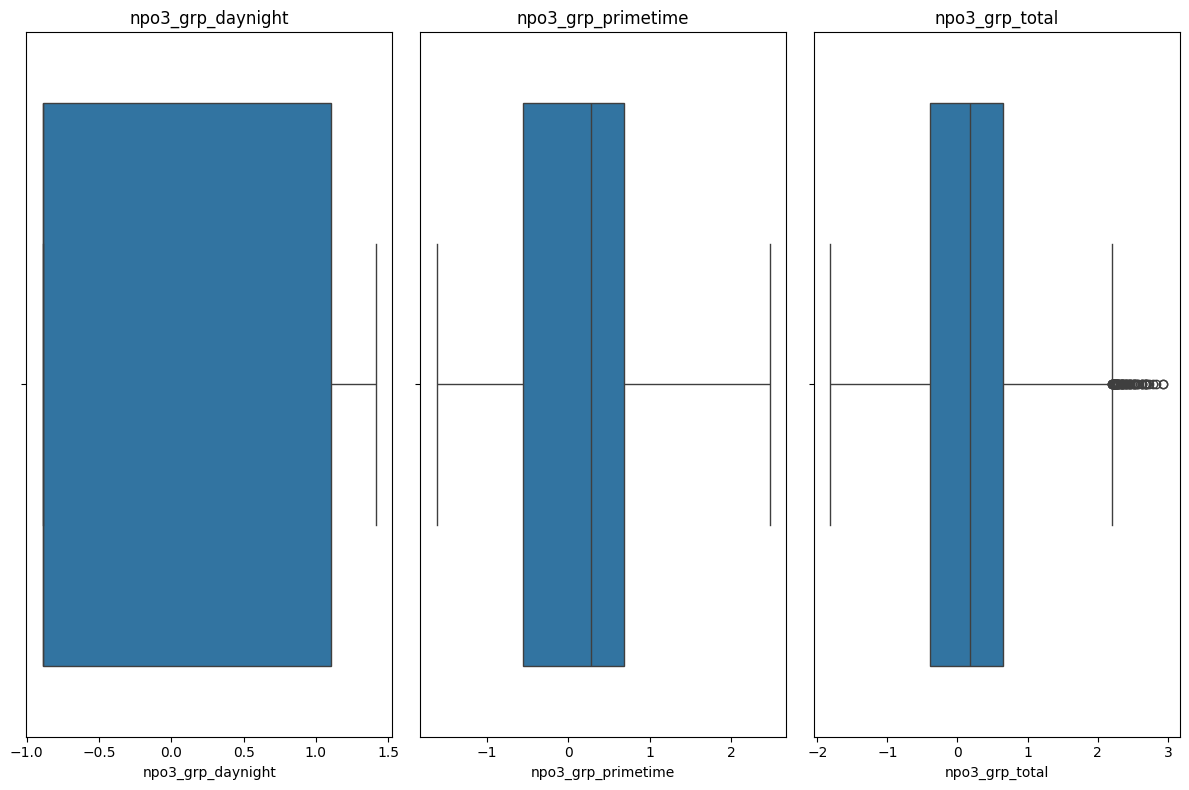

In [20]:
import seaborn as sns
plt.figure(figsize=(7, 5))
sns.histplot(trainer.df['ster_1+_total'], kde=True, bins=30)
plt.title('Distribution of Target Variable')
plt.xlabel('Target Variable')
plt.ylabel('Frequency')
plt.show()

# Boxplot for 'npo3_grp_daynight'
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)  # 1 row, 3 columns, 1st subplot
sns.histplot(trainer.df['npo3_grp_daynight'], kde=True, bins=30)
plt.title('npo3_grp_daynight')

# Boxplot for 'npo3_grp_primetime'
plt.subplot(1, 3, 2)  # 1 row, 3 columns, 2nd subplot
sns.histplot(trainer.df['npo3_grp_primetime'], kde=True, bins=30)
plt.title('npo3_grp_primetime')

# Boxplot for 'npo3_grp_total'
plt.subplot(1, 3, 3)  # 1 row, 3 columns, 3rd subplot
sns.histplot(trainer.df['npo3_grp_total'], kde=True, bins=30)
plt.title('npo3_grp_total')

plt.tight_layout()

plt.figure(figsize=(7, 5))
sns.boxplot(x=trainer.df['ster_1+_total'])
plt.title('Box Plot of Target Variable')
plt.xlabel('Target Variable')
plt.show()

# Boxplot for 'npo3_grp_daynight'
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)  # 1 row, 3 columns, 1st subplot
sns.boxplot(x=trainer.df['npo3_grp_daynight'])
plt.title('npo3_grp_daynight')

# Boxplot for 'npo3_grp_primetime'
plt.subplot(1, 3, 2)  # 1 row, 3 columns, 2nd subplot
sns.boxplot(x=trainer.df['npo3_grp_primetime'])
plt.title('npo3_grp_primetime')

# Boxplot for 'npo3_grp_total'
plt.subplot(1, 3, 3)  # 1 row, 3 columns, 3rd subplot
sns.boxplot(x=trainer.df['npo3_grp_total'])
plt.title('npo3_grp_total')

plt.tight_layout()
plt.show();

In [21]:
# Define bins (you can adjust these as needed)
df=trainer.df
bin_edges = [0, 1, 2, 3, 4, float('inf')]
df['grp_feature_binned'] = pd.cut(df['npo3_grp_daynight'], bins=bin_edges)

# Count instances in each bin
bin_counts = df['grp_feature_binned'].value_counts().sort_index()

print(bin_counts)

grp_feature_binned
(0.0, 1.0]     2923
(1.0, 2.0]    15272
(2.0, 3.0]        0
(3.0, 4.0]        0
(4.0, inf]        0
Name: count, dtype: int64


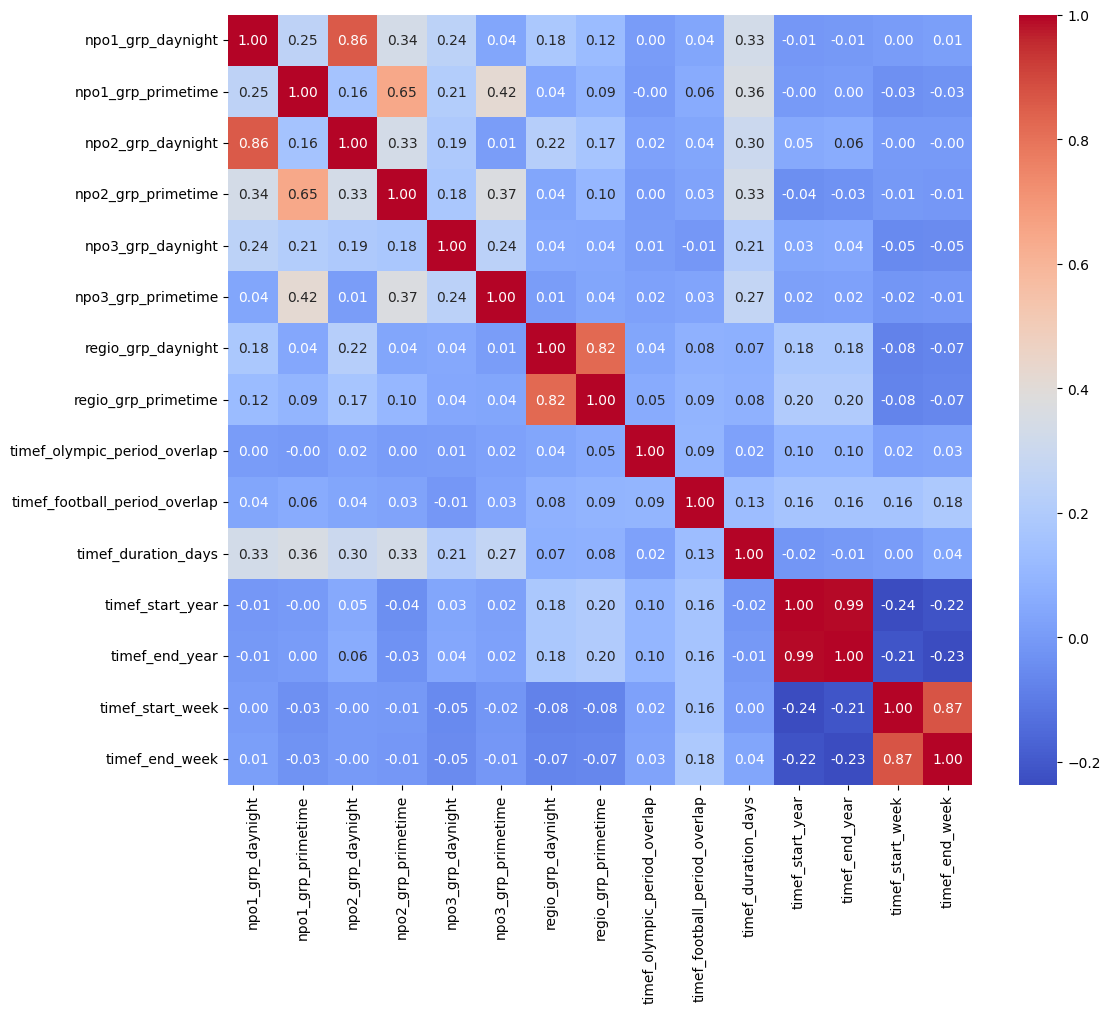

In [22]:
corr_matrix = trainer.df[NUMERICAL_COLS].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show();

## Data Check

In [23]:
trainer.split_and_shuffle_data(trainer.df, trainer.test_set_date if trainer.split_type == 'timeseries' else None)
trainer.X_train.head(3)
trainer.X_test.head(3)

,npo1_grp_daynight,npo1_grp_primetime,npo2_grp_daynight,npo2_grp_primetime,npo3_grp_daynight,npo3_grp_primetime,regio_grp_daynight,regio_grp_primetime,timef_olympic_period_overlap,timef_football_period_overlap,timef_duration_days,timef_start_year,timef_end_year,timef_start_week,timef_end_week,alcohol_kansspelen,new_data
16202,123.91,173.60,22.14,26.24,1.070047,0.159630,0.0,0.0,0,0,11,2021,2021,53,2,True,0
29828,0.00,221.72,0.00,154.05,-0.888138,0.467084,0.0,0.0,0,0,11,2021,2021,53,2,True,0
2711,415.51,44.36,112.16,585.14,-0.888138,1.121849,0.0,0.0,0,0,59,2021,2021,53,8,True,0


,npo1_grp_daynight,npo1_grp_primetime,npo2_grp_daynight,npo2_grp_primetime,npo3_grp_daynight,npo3_grp_primetime,regio_grp_daynight,regio_grp_primetime,timef_olympic_period_overlap,timef_football_period_overlap,timef_duration_days,timef_start_year,timef_end_year,timef_start_week,timef_end_week,alcohol_kansspelen,new_data
26702,36.65,332.05,17.77,47.14,-0.888138,0.774897,1.97,1.75,0,0,6,2024,2024,9,10,False,1
22080,23.59,18.31,19.96,24.37,1.148429,0.014904,1.78,0.50,0,0,37,2024,2024,9,14,False,1
38414,191.17,58.51,18.97,54.82,1.089249,0.764306,0.62,1.56,0,0,38,2024,2024,9,14,False,1


## Training Model

In [24]:
trainer.grid_search_models()

Fitting 5 folds for each of 1 candidates, totalling 5 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003138 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11690
[LightGBM] [Info] Number of data points in the train set: 36206, number of used features: 16
[LightGBM] [Info] Start training from score 53.059306


15:00:58 - INFO - TEST_SET_DATE: 2024-03-01 00:00:00


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


15:00:58 - INFO - CUT_OFF_DATE: 2021-01-01 
15:00:58 - INFO - TARGET_GROUPS: ['68+'] 
15:00:58 - INFO - FEATURES: ['npo1_grp_daynight', 'npo1_grp_primetime', 'npo2_grp_daynight', 'npo2_grp_primetime', 'npo3_grp_daynight', 'npo3_grp_primetime', 'regio_grp_daynight', 'regio_grp_primetime', 'timef_olympic_period_overlap', 'timef_football_period_overlap', 'timef_duration_days', 'timef_start_year', 'timef_end_year', 'timef_start_week', 'timef_end_week', 'alcohol_kansspelen', 'new_data'] 
15:00:58 - INFO - Scoring: neg_mean_squared_error 
15:00:58 - INFO - Split-type: timeseries 
15:00:58 - INFO - X_train shape: (36206, 17), X_test shape: (1182, 17), y_train shape: (36206,), y_test shape: (1182,)
15:00:58 - INFO - Best Parameters for All Models:
15:00:58 - INFO - LGBM without scaling 25-67:
15:00:58 - INFO -   model__boosting_type: gbdt
15:00:58 - INFO -   model__colsample_bytree: 1.0
15:00:58 - INFO -   model__drop_rate: 0.2
15:00:58 - INFO -   model__learning_rate: 0.07
15:00:58 - INFO -  

In [25]:
trainer.models_df

,Model,Parameters,R2 Train,R2 Test,MSE Train,MSE Test,MAE Train,MAE Test
0,LGBM without scaling 25-67,"{'model__boosting_type': 'gbdt', 'model__colsample_bytree': 1.0, 'model__drop_rate': 0.2, 'model__learning_rate': 0.07, 'model__max_bin': 2048, 'model__max_depth': 6, 'model__metric': 'rmse', 'model__min_split_gain': 0.0, 'model__n_estimators': 100, 'model__num_leaves': 41, 'model__objective': 'regression', 'model__reg_alpha': 2.5, 'model__reg_lambda': 2, 'model__seed': 42, 'model__subsample': 0.5, 'model__subsample_freq': 1, 'model__verbose': 1}",0.953059,0.945582,21.584908,24.461701,3.566575,3.729227


## SHAP Visuals

npo1_grp_primetime     11.745871
npo1_grp_daynight       5.693454
npo2_grp_primetime      3.086759
timef_duration_days     1.558240
npo2_grp_daynight       1.464582
npo3_grp_primetime      0.864738
timef_end_week          0.569965
timef_start_year        0.532413
regio_grp_daynight      0.289231
npo3_grp_daynight       0.276848
dtype: float64


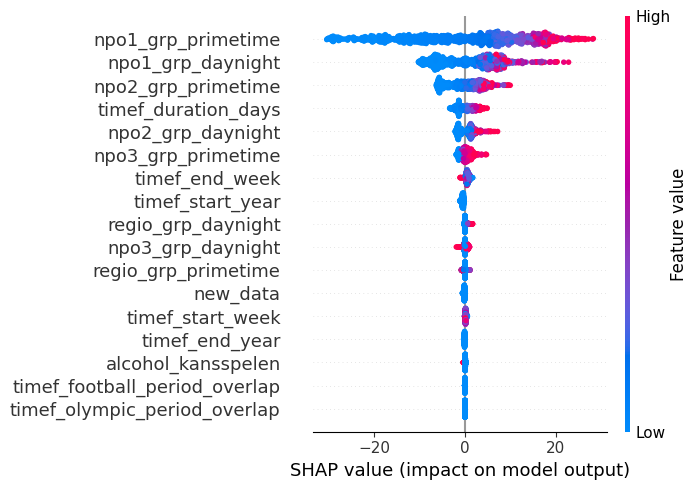

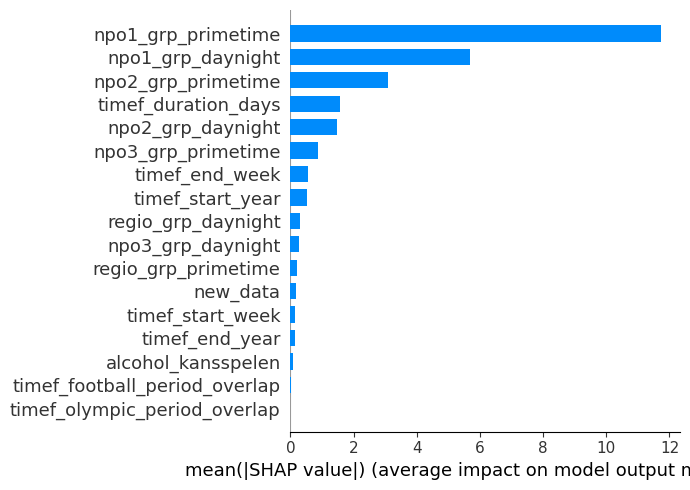

npo1_grp_daynight                 191.170000
npo1_grp_primetime                 58.510000
npo2_grp_daynight                  18.970000
npo2_grp_primetime                 54.820000
npo3_grp_daynight                   1.089249
npo3_grp_primetime                  0.764306
regio_grp_daynight                  0.620000
regio_grp_primetime                 1.560000
timef_olympic_period_overlap        0.000000
timef_football_period_overlap       0.000000
timef_duration_days                38.000000
timef_start_year                 2024.000000
timef_end_year                   2024.000000
timef_start_week                    9.000000
timef_end_week                     14.000000
alcohol_kansspelen                  0.000000
new_data                            1.000000
Name: 2, dtype: float64


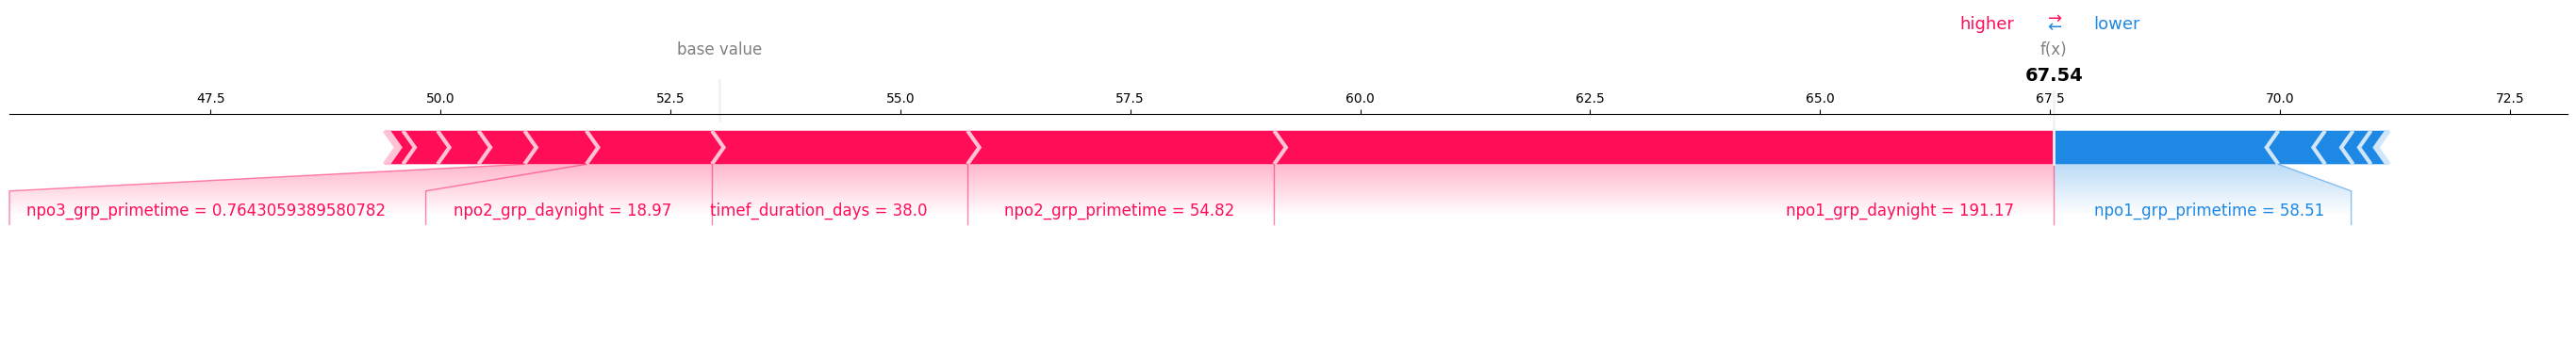

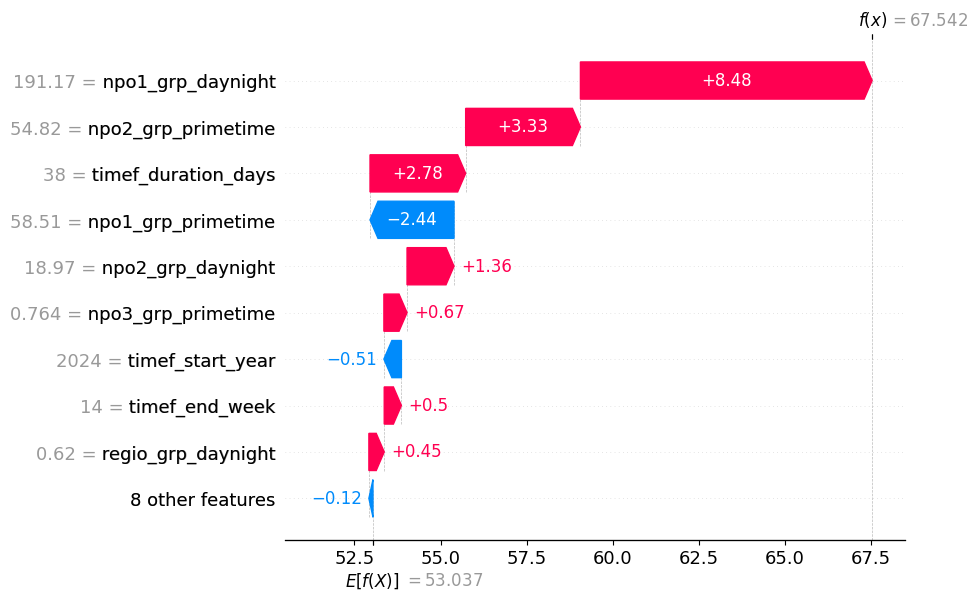

In [26]:
trainer.extract_and_visualize_shap_values(top_n = 10, plot_instance = 2)

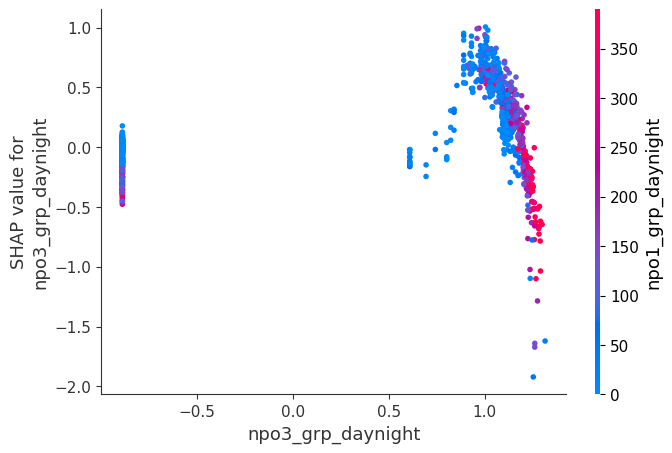

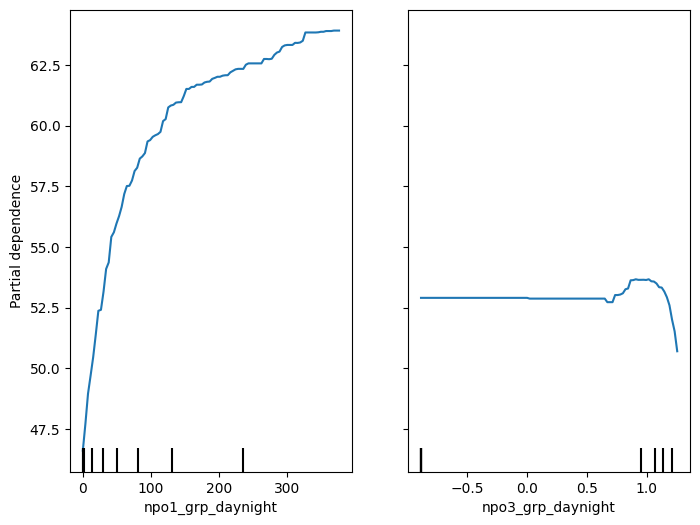

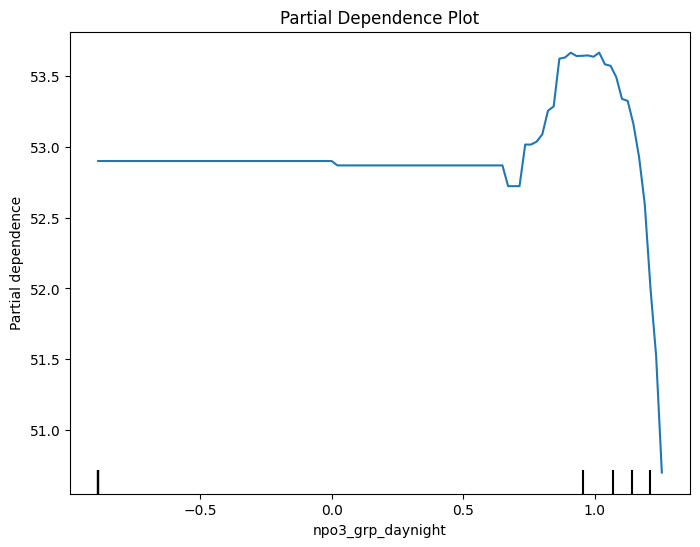

In [27]:
trainer.plot_dependence("npo3_grp_daynight")

## Predictions

In [30]:
def prep_dataframe_for_testing(df_bereik):
    from sklearn.preprocessing import PowerTransformer

    df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                    "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                    "ster_1+"]].reset_index(drop=True)

    df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                        columns='daypart', fill_value=0.0,
                        values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())

    df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

    # Convert start_date and end_date to datetime objects and calculate required values
    df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
    df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

    # Apply function to create extra columns
    df['timef_start_month'] = df['start_date'].dt.month
    df['timef_end_month'] = df['end_date'].dt.month
    df['timef_start_year'] = df['start_date'].dt.year
    df['timef_end_year'] = df['end_date'].dt.year
    df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
    df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
    df['timef_start_day'] = df['start_date'].dt.day
    df['timef_end_day'] = df['end_date'].dt.day
    df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

    df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')
    df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                'Spring' if month in [3, 4, 5] else
                                                'Summer' if month in [6, 7, 8] else
                                                'Autumn')

    # Calculate total overlap with olympics and WK/EK
    df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
    df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

    # Create a new column 'new_data' indicating old or new
    df['new_data'] = pd.cut(
        df['start_date'],
        bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
        labels=[0, 1])

    df = df.sort_values(by='start_date')

    # transform NPO3 GRPS
    pt = PowerTransformer(method='box-cox')
    constant = 1e-6  # Small constant to shift the data
    df['npo3_grp_daynight'] += constant
    df['npo3_grp_primetime'] += constant
    df['npo3_grp_total'] += constant

    df['npo3_grp_daynight'] = pt.fit_transform(df[['npo3_grp_daynight']])
    df['npo3_grp_primetime'] = pt.fit_transform(df[['npo3_grp_primetime']])
    df['npo3_grp_total'] = pt.fit_transform(df[['npo3_grp_total']])

    return df

query = """
    SELECT b.flight_id,
            b.target_group,
            f.advertiser,
            f.product,
            f.start_date,
            f.end_date,
            b.campaign_duration,
            b.daypart,
            f.mock_campaign,
            f.alcohol_kansspelen,
            b.total_grp,
            b.ster_grp,
            b.regio_grp,
            b.npo1_grp,
            b.npo2_grp,
            b.npo3_grp,
            b.[ster_1+]
    FROM [dbo].[tv.bereik_ster] b
    LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
    WHERE b.ster_grp > 0 AND target_group = '68+'
    AND YEAR(f.start_date) = 2024
    AND MONTH(f.start_date) = 5
    ORDER BY start_date
    """
# trainer.predict_new_data(query)
df = trainer.query_to_df(query)
new_df = prep_dataframe_for_testing(df)
X_new = new_df[trainer.features]

# Preprocess the new data using the same preprocessor used in the best model
X_preprocessed = trainer.best_model.named_steps['preprocessor'].transform(X_new)

# Predict using the best model
prediction = trainer.best_model.named_steps['model'].predict(X_preprocessed)

# Prepare the results DataFrame
results_df = X_new.copy()
results_df['prediction'] = prediction

results_df['ster_1+_total'] = new_df['ster_1+_total']
# Calculate residuals
results_df['residuals'] = results_df['ster_1+_total'] - results_df['prediction']

results_df[['ster_1+_total', 'prediction', 'residuals']] = results_df[['ster_1+_total', 'prediction', 'residuals']].round(1)

results_df = results_df[['npo1_grp_daynight', 'npo1_grp_primetime', 'npo2_grp_daynight', 'npo2_grp_primetime',
                         'timef_olympic_period_overlap', 'timef_football_period_overlap', 'timef_duration_days',
                         'ster_1+_total', 'prediction', 'residuals']]

# Save the results to an Excel file
results_df.to_excel('results_df.xlsx', index=False)

In [ ]:
# single prediction:

# data = {
#     'timef_olympic_period': [0],
#     'timef_football_period': [0],
#     'timef_start_year': timef_start_year,
#     'timef_end_year': timef_end_year,
#     'timef_start_month': timef_start_month,
#     'timef_end_month': timef_end_month,
#     'timef_start_week': timef_start_week,
#     'timef_end_week': timef_end_week,
#     'timef_start_day': timef_start_day,
#     'timef_end_day': timef_end_day,
#     'timef_duration_days': timef_duration_days,
#     'meta_second_spot_duration': [0],
#     'meta_alcohol_adv': [0],
#     'meta_kansspelen_adv': [0],
#     'NPO_1_primetime_GRP': NPO_1_primetime_GRP,
#     'NPO_1_daynight_GRP': NPO_1_daynight_GRP,
#     'NPO_2_primetime_GRP': NPO_2_primetime_GRP,
#     'NPO_2_daynight_GRP': NPO_2_daynight_GRP,
#     'NPO_3_primetime_GRP': NPO_3_primetime_GRP,
#     'NPO_3_daynight_GRP': NPO_3_daynight_GRP
# }

In [ ]:
'''
MODEL_PARAMS = [

    {
        'name': 'LGBM without scaling',
        'model': LGBMRegressor(objective='regression'),
        'params': {
            'model__metric': ['rmse'],
            'model__num_leaves': [41],
            'model__max_depth': [4],
            # 'model__min_data_in_leaf': [20, 50, 80],
            # 'model__min_sum_hessian_in_leaf': [1e-3, 1e-2, 1e-1],
            # 'model__feature_fraction': [0.8, 1.0],
            # 'model__bagging_fraction': [0.8, 1.0],
            # 'model__learning_rate': [0.01, 0.05],
            'model__lambda_l1': [0.1, 0.5],
            'model__lambda_l2': [0.1, 0.5],
            'model__max_bin': [255, 511],
            'model__verbose': [1],
            'model__seed': [42]
        },
        'scaling': 'unscaled'
    },
    # {
    #     'name': 'Gradient Boosting Regressor without scaling',
    #     'model': GradientBoostingRegressor(),
    #     'params': {
    #         'model__learning_rate': [0.03],
    #         'model__max_depth': [5],
    #         'model__max_features': ['sqrt'],
    #         'model__min_samples_leaf': [1],
    #         'model__min_samples_split': [10],
    #         'model__n_estimators': [200],
    #         'model__verbose': [1],
    #         'model__random_state': [42],
    #         'model__subsample': [0.8]
    #     },
    #     'scaling': 'unscaled'
    # },
    # {
    #     'name': 'Hist Gradient Boosting Regressor without scaling',
    #     'model': HistGradientBoostingRegressor(),
    #     'params': {
    #         'model__max_iter': [75, 100, 125],
    #         'model__learning_rate': [0.01, 0.1],
    #         'model__max_depth': [5, 8, 10],
    #         'model__verbose': [1],
    #         'model__random_state': [42]
    #     },
    #     'scaling': 'unscaled'
    # }
]
'''